# E7: CRNN | 64 Mel bins | có SpecAugment
Nhánh GitHub: `10-E7-crnn-mel64-specaug`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [ ]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [ ]:
EXP_ID = "E7"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'crnn', 'n_mels': 64, 'specaug': True}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [ ]:
lr = search_lr(EXP_ID)

train:   0%|          | 0/40 [00:00<?, ?it/s]

E7 {'LR': 0.0003, 'EPOCHS': 40} -> 0.7653


train:   0%|          | 0/40 [00:00<?, ?it/s]

E7 {'LR': 0.001, 'EPOCHS': 40} -> 0.7548


,LR,EPOCHS,val_macro_f1,best_epoch
0,0.0003,40,0.765324,37
1,0.0010,40,0.754820,39


E7: learning rate được chọn = 0.0003


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [ ]:
runs, rob = run_exp(EXP_ID, lr)

E7 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E7 | fold 1] acc 0.7775 | macro-F1 0.7644 | lr 0.0003 | epoch tốt nhất 70 | 104s


E7 | fold 2:   0%|          | 0/80 [00:00<?, ?it/s]

[E7 | fold 2] acc 0.8075 | macro-F1 0.8015 | lr 0.0003 | epoch tốt nhất 67 | 105s


E7 | fold 3:   0%|          | 0/80 [00:00<?, ?it/s]

[E7 | fold 3] acc 0.7925 | macro-F1 0.7891 | lr 0.0003 | epoch tốt nhất 70 | 104s


E7 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E7 | fold 4] acc 0.8150 | macro-F1 0.8100 | lr 0.0003 | epoch tốt nhất 64 | 104s


E7 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E7 | fold 5] acc 0.7800 | macro-F1 0.7689 | lr 0.0003 | epoch tốt nhất 75 | 105s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.7775,0.7644,0.0003,70,0.8025,104.4584
1,2,0.8075,0.8015,0.0003,67,0.8168,104.5133
2,3,0.7925,0.7891,0.0003,70,0.8229,104.3456
3,4,0.8150,0.8100,0.0003,64,0.7491,104.4752
4,5,0.7800,0.7689,0.0003,75,0.7988,104.6408


E7: Accuracy 79.45 ± 1.65 | Macro-F1 78.68 ± 1.99 | 2,071,762 tham số


,acc,macro_f1
condition,,
Sạch,79.45,78.68
20 dB,64.75,64.11
10 dB,37.90,38.64
0 dB,7.40,7.01


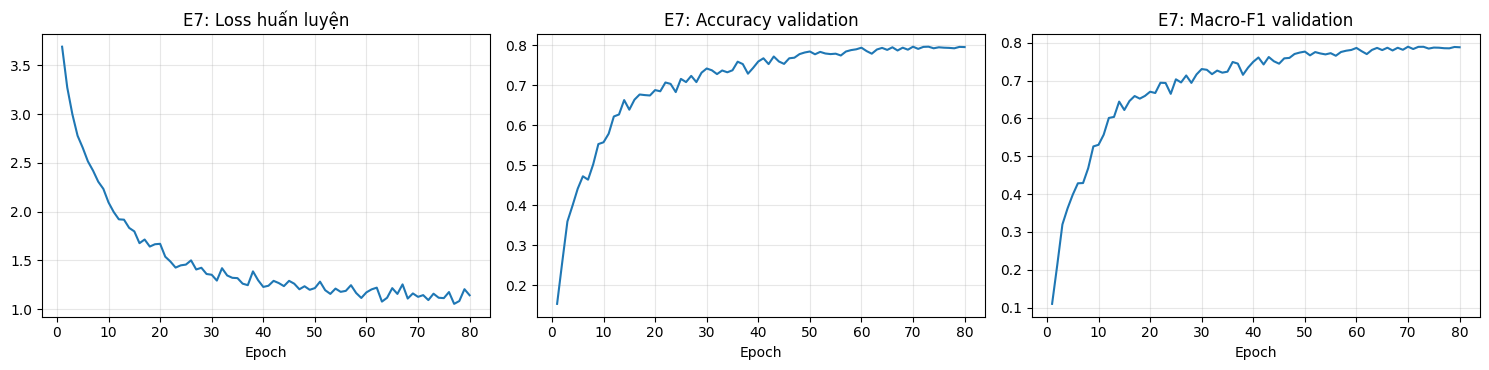

In [ ]:
show_exp(EXP_ID)